In [1]:
import time
from pathlib import Path
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
RAW = ROOT / "data" / "raw"; RAW.mkdir(parents=True, exist_ok=True)
GRID, HOURS, ROAD_THRESH = 8, 72, 0.7     # 0.7 = value picked by calibration earlier


def build_graph(rng, grid=GRID):
    G = nx.grid_2d_graph(grid, grid)
    nodes = list(G.nodes)
    rng.shuffle(nodes)
    shelters, depots = set(nodes[:8]), set(nodes[8:11])
    slope = rng.uniform(-1, 1, size=2)
    for (x, y) in G.nodes:
        elev = 5 + slope[0] * x / grid * 3 + slope[1] * y / grid * 3 + rng.normal(0, 0.4)
        G.nodes[(x, y)]["elevation"] = elev
        if (x, y) in shelters:
            G.nodes[(x, y)].update(ntype="shelter", population=0,
                                   capacity=int(rng.integers(2500, 7000)), inventory=0.0)
        elif (x, y) in depots:
            G.nodes[(x, y)].update(ntype="depot", population=0, capacity=0,
                                   inventory=float(rng.integers(8000, 20000)))
        else:
            pop = int(rng.integers(500, 4000))
            days = rng.uniform(1.5, 6.0)
            G.nodes[(x, y)].update(ntype="zone", population=pop, capacity=0,
                                   inventory=pop * 0.01 * 24 * days)
    for u, v in G.edges:
        G.edges[u, v]["length_km"] = float(rng.uniform(0.8, 2.5))
    return G


def make_rainfall(rng, hours=HOURS):
    t = np.arange(hours)
    base = rng.gamma(1.5, 0.6, size=hours)
    peak_t = rng.integers(12, 40)
    width = rng.uniform(4, 10)
    intensity = rng.uniform(15, 55)
    return base + intensity * np.exp(-0.5 * ((t - peak_t) / width) ** 2)


def add_failure_labels(df, horizon=6):
    # no groupby().apply(): new pandas drops the group columns
    df = df.sort_values(["scenario", "node", "hour"]).reset_index(drop=True)
    df["failed_now"] = ((df["isolated"] == 1) |
                        (df["days_of_supply"] < 0.25) |
                        (df["nearest_shelter_occ"] > 1.0)).astype(int)
    failed = df["failed_now"].to_numpy()
    tt = np.zeros(len(df))
    for idx in df.groupby(["scenario", "node"]).indices.values():
        f = failed[idx]
        T = len(f)
        out = np.full(T, float(T))          # censored: no failure observed
        nxt = None
        for i in range(T - 1, -1, -1):
            if f[i]:
                nxt = i
            if nxt is not None:
                out[i] = nxt - i
        tt[idx] = out
    df["hours_to_failure"] = tt
    df["will_fail_within_6h"] = (tt <= horizon).astype(int)
    return df


def run_simulation(seed, interventions=None, hours=HOURS, road_thresh=ROAD_THRESH):
    rng = np.random.default_rng(seed)
    G = build_graph(rng)
    rain = make_rainfall(rng, hours)
    interventions = interventions or {}

    for node, amt in interventions.get("extra_supply", {}).items():
        if node in G.nodes:
            G.nodes[node]["inventory"] += amt
    for node in interventions.get("open_shelter", []):
        if node in G.nodes:
            G.nodes[node].update(ntype="shelter", capacity=4000)
    forced_open = set(map(frozenset, interventions.get("restore_roads", [])))

    nodes = list(G.nodes)
    depth = {n: 0.0 for n in nodes}
    occupancy = {n: 0 for n in nodes}
    inventory = {n: G.nodes[n]["inventory"] for n in nodes}
    displaced_total = {n: 0 for n in nodes}
    rows = []

    for h in range(hours):
        new_depth = {}
        for n in nodes:
            nb = [depth[m] for m in G.neighbors(n)]
            inflow = rain[h] / 1000 * (1.0 + max(0, 5.2 - G.nodes[n]["elevation"]))
            spread = 0.15 * (np.mean(nb) - depth[n]) if nb else 0.0
            drain = 0.03 * depth[n] + 0.01
            new_depth[n] = max(0.0, depth[n] + inflow + spread - drain)
        depth = new_depth

        for u, v in G.edges:
            avg = (depth[u] + depth[v]) / 2
            G.edges[u, v]["failed"] = bool(avg > road_thresh and frozenset((u, v)) not in forced_open)

        open_G = nx.Graph([(u, v) for u, v in G.edges if not G.edges[u, v]["failed"]])
        open_G.add_nodes_from(nodes)
        shelters = [n for n in nodes if G.nodes[n]["ntype"] == "shelter"]

        comp = {}
        for i, c in enumerate(nx.connected_components(open_G)):
            for n in c:
                comp[n] = i
        shelter_comps = {comp[s] for s in shelters}

        hour_rows = []
        for n in nodes:
            nd = G.nodes[n]
            if nd["ntype"] != "zone":
                continue
            frac = min(1.0, max(0.0, (depth[n] - 0.3) / 1.5))
            displaced = int(nd["population"] * frac)
            newly = max(0, displaced - displaced_total[n])
            displaced_total[n] = max(displaced_total[n], displaced)
            requests = int(rng.poisson(0.002 * nd["population"] * depth[n] * 3))

            consumption = (nd["population"] + 0.5 * displaced) * 0.01
            inventory[n] = max(0.0, inventory[n] - consumption)
            base_daily = max(nd["population"] * 0.01 * 24, 1e-9)

            nearest, dist = None, np.inf
            if comp[n] in shelter_comps:
                cands = [s for s in shelters if comp[s] == comp[n]]
                nearest = min(cands, key=lambda s: nx.shortest_path_length(open_G, n, s))
                dist = nx.shortest_path_length(open_G, n, nearest)
                if newly > 0:
                    occupancy[nearest] += newly

            open_roads = sum(not G.edges[n, m]["failed"] for m in G.neighbors(n))
            hour_rows.append(dict(
                scenario=seed, hour=h, node=f"{n[0]}_{n[1]}", x=n[0], y=n[1],
                population=nd["population"], elevation=nd["elevation"],
                rain_mm=rain[h], flood_depth=depth[n],
                displaced=displaced, requests=requests,
                inventory=inventory[n],
                days_of_supply=inventory[n] / base_daily,
                open_road_frac=open_roads / max(1, G.degree(n)),
                isolated=int(nearest is None),
                shelter_dist=dist if np.isfinite(dist) else 99,
                nearest_shelter_occ=0.0,
                _shelter=nearest,
            ))

        # each zone gets the occupancy of its OWN nearest shelter (not the global max)
        ratio = {s: occupancy[s] / max(1, G.nodes[s]["capacity"]) for s in shelters}
        for r in hour_rows:
            s = r.pop("_shelter")
            r["nearest_shelter_occ"] = ratio[s] if s is not None else 0.0
        rows.extend(hour_rows)

    return add_failure_labels(pd.DataFrame(rows))


print("simulator ready:", callable(run_simulation), "| data folder:", RAW)
SCN = ROOT / "data" / "scenarios"; SCN.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)


simulator ready: True | data folder: /home/ibm-user/floodguard/data/raw


In [4]:
def node_t(s):
    x, y = s.split("_"); return int(x), int(y)

def metrics(d):
    return {"people_hours_failed": int((d["population"] * d["failed_now"]).sum()),
            "isolated_pop_hours": int((d["population"] * d["isolated"]).sum()),
            "failed_zone_hours": int(d["failed_now"].sum()),
            "zones_ever_failed": int(d.groupby("node")["failed_now"].max().sum())}

def strat_supply(base, k=12):        # 3 extra days of supply in the k worst zones
    worst = base.groupby("node")["failed_now"].sum().sort_values(ascending=False).head(k).index
    pop = base.groupby("node")["population"].first()
    return {"extra_supply": {node_t(n): float(pop[n] * 0.01 * 24 * 3) for n in worst}}

def strat_shelter(base, G, k_open=2, k_zones=10):   # open depots closest to the worst zones
    worst = base.groupby("node")["failed_now"].sum().sort_values(ascending=False).head(k_zones).index
    depots = [n for n in G.nodes if G.nodes[n]["ntype"] == "depot"]
    sc = lambda dp: sum(1 / (1 + abs(dp[0] - node_t(z)[0]) + abs(dp[1] - node_t(z)[1])) for z in worst)
    return {"open_shelter": sorted(depots, key=sc, reverse=True)[:k_open]}

def strat_roads(base, G, k=6):       # restore roads around the longest-isolated zones
    worst = base.groupby("node")["isolated"].sum().sort_values(ascending=False).head(k)
    return {"restore_roads": [(node_t(n), m) for n in worst[worst > 0].index for m in G.neighbors(node_t(n))]}

def merge(*plans):
    out = {"extra_supply": {}, "open_shelter": [], "restore_roads": []}
    for p in plans:
        out["extra_supply"].update(p.get("extra_supply", {}))
        out["open_shelter"] += p.get("open_shelter", [])
        out["restore_roads"] += p.get("restore_roads", [])
    return out
print("strategies ready")

strategies ready


In [5]:
t0 = time.time()
base_runs = {s: run_simulation(s) for s in range(40)}
fr = pd.Series({s: d["failed_now"].mean() for s, d in base_runs.items()})
SEEDS = list(fr.sort_values(ascending=False).head(15).index)      # 15 most severe of 40

rows = []
for seed in SEEDS:
    base = base_runs[seed]
    G = build_graph(np.random.default_rng(seed))                    # same seed = same city
    ps, ph, pr = strat_supply(base), strat_shelter(base, G), strat_roads(base, G)
    plans = {"baseline (do nothing)": None, "pre-position supplies": ps, "open extra shelters": ph,
             "restore roads": pr, "all three combined": merge(ps, ph, pr)}
    for name, iv in plans.items():
        d = base if iv is None else run_simulation(seed, interventions=iv)
        rows.append({"scenario": seed, "strategy": name, **metrics(d)})
res = pd.DataFrame(rows)
print(f"done in {time.time()-t0:.0f}s | {len(res)} runs")

done in 57s | 75 runs


                       people_hours_failed  isolated_pop_hours  \
strategy                                                         
baseline (do nothing)              3617305             1198000   
pre-position supplies              3532814             1198000   
open extra shelters                2965191             1198000   
restore roads                      3613047              811709   
all three combined                 2794547              811709   

                       failed_zone_hours  zones_ever_failed  
strategy                                                     
baseline (do nothing)               1584                 43  
pre-position supplies               1549                 43  
open extra shelters                 1298                 39  
restore roads                       1582                 43  
all three combined                  1223                 37  

% reduction vs doing nothing:
                        people_hours_failed  isolated_pop_hours  \
strat

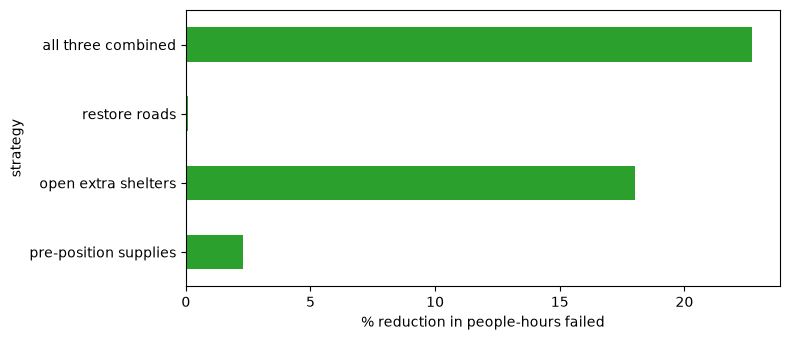

In [6]:
order = ["baseline (do nothing)", "pre-position supplies", "open extra shelters", "restore roads", "all three combined"]
cols = ["people_hours_failed", "isolated_pop_hours", "failed_zone_hours", "zones_ever_failed"]
summ = res.groupby("strategy")[cols].mean().loc[order]
pct = ((1 - summ / summ.loc["baseline (do nothing)"].replace(0, np.nan)) * 100).round(1)
print(summ.round(0).astype(int)); print("\n% reduction vs doing nothing:\n", pct)

piv = res.pivot(index="scenario", columns="strategy", values="people_hours_failed")
print("\nScenarios improved (of 15):", {s: int((piv[s] < piv["baseline (do nothing)"]).sum()) for s in order[1:]})
res.to_csv(SCN / "whatif_results.csv", index=False)

pct["people_hours_failed"].iloc[1:].plot.barh(figsize=(8, 3.5), color="#2ca02c")
plt.xlabel("% reduction in people-hours failed"); plt.tight_layout()
plt.savefig(FIG / "whatif_comparison.png", dpi=120); plt.show()

In [7]:
import joblib
MOD = ROOT / "models"
FEATURES = joblib.load(MOD / "features.joblib")
clf = joblib.load(MOD / "failure_clf.joblib")

def add_features(d):
    """Same features as notebook 03. Uses past values only, so scoring hour T never peeks ahead."""
    d = d.sort_values(["node", "hour"]).reset_index(drop=True)
    g = d.groupby("node")
    d["depth_rise_1h"] = d["flood_depth"] - g["flood_depth"].shift(1)
    d["depth_rise_3h"] = d["flood_depth"] - g["flood_depth"].shift(3)
    d["requests_trend"] = d["requests"] - g["requests"].shift(3)
    d["supply_burn_3h"] = g["days_of_supply"].shift(3) - d["days_of_supply"]
    d["occ_trend"] = d["nearest_shelter_occ"] - g["nearest_shelter_occ"].shift(3)
    d["road_loss_3h"] = g["open_road_frac"].shift(3) - d["open_road_frac"]
    rain = d.drop_duplicates("hour").set_index("hour")["rain_mm"].sort_index()
    d["rain_3h"] = d["hour"].map(rain.rolling(3, min_periods=1).sum())
    d["rain_6h"] = d["hour"].map(rain.rolling(6, min_periods=1).sum())
    d[FEATURES] = d[FEATURES].fillna(0).astype("float32")
    d["risk_6h"] = clf.predict_proba(d[FEATURES])[:, 1]
    return d

K = 12   # every strategy protects the same number of zones

def zones_model(base, T):
    d = add_features(base)
    now = d[(d["hour"] == T) & (d["failed_now"] == 0)]
    return [str(z) for z in now.sort_values(["risk_6h", "population"], ascending=False).head(K)["node"]]

def zones_oracle(base):
    return [str(z) for z in base.groupby("node")["failed_now"].sum().sort_values(ascending=False).head(K).index]

def zones_random(base, rng):
    return [str(z) for z in rng.choice(base["node"].unique(), K, replace=False)]

def plan_for(zones, base, G):
    """Same three actions for every strategy, aimed at the chosen zones."""
    pop = base.groupby("node")["population"].first()
    supply = {node_t(n): float(pop[n] * 0.01 * 24 * 3) for n in zones}
    depots = [n for n in G.nodes if G.nodes[n]["ntype"] == "depot"]
    sc = lambda dp: sum(1 / (1 + abs(dp[0] - node_t(z)[0]) + abs(dp[1] - node_t(z)[1])) for z in zones)
    shelters = sorted(depots, key=sc, reverse=True)[:2]
    roads = [(node_t(n), m) for n in zones[:6] for m in G.neighbors(node_t(n))]
    return {"extra_supply": supply, "open_shelter": shelters, "restore_roads": roads}

print("ready | model loaded, features:", len(FEATURES))

ready | model loaded, features: 19


In [10]:
DECISION_HOUR = 16     # the moment the coordinator decides; failures mostly start later
t0 = time.time()

runs2 = {s: run_simulation(s) for s in range(2000, 2040)}                 # fresh, unseen floods
fr2 = pd.Series({s: d["failed_now"].mean() for s, d in runs2.items()})
SEEDS2 = list(fr2.sort_values(ascending=False).head(15).index)            # 15 most severe
print(f"base runs done in {time.time()-t0:.0f}s")

rows = []
for seed in SEEDS2:
    base = runs2[seed]
    G = build_graph(np.random.default_rng(seed))
    rng = np.random.default_rng(seed)
    plans = {"do nothing": None,
             "model-targeted": plan_for(zones_model(base, DECISION_HOUR), base, G),
             "oracle (hindsight)": plan_for(zones_oracle(base), base, G)}
    for r in range(3):                                                    # 3 random draws, averaged later
        plans[f"random #{r}"] = plan_for(zones_random(base, rng), base, G)
    for name, iv in plans.items():
        d = base if iv is None else run_simulation(seed, interventions=iv)
        rows.append({"scenario": seed, "strategy": name.split(" #")[0], **metrics(d)})

res2 = pd.DataFrame(rows).groupby(["scenario", "strategy"]).mean().reset_index()
print(f"done in {time.time()-t0:.0f}s")

base runs done in 23s
done in 69s
